# 📝 ¿Qué variables tienen mayor impacto al predecir futuros morosos y qué tener en cuenta para no rechazar a buenos pagadores?

 Dataset disponible: https://www.kaggle.com/datasets/rohitudageri/credit-card-details/data

**Objetivo:**
Un banco sufre a diario impagos de clientes en sus tarjetas de crédito por no haber considerado ciertos factores que hacían a estas personas clientes riesgosos. Mi objetivo es dar solución a este problema al predecir a este grupo de personas mediante sus datos demográficos y financieros y, a su vez, reducir los rechazos a personas que pagarán correctamente, evitando que estos se vayan a la competencia.


**Preguntas de negocio:**


¿La antiguedad laboral es un factor determinante para aprobar una tarjeta de crédito?


¿Tener posesiones influye para ser aprobado?


¿A mayor ingreso anual existe menos riesgo de ser rechazado?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno

ruta = '../../Data/Credit Card Clasification Problem/archive/'

In [2]:
df = pd.read_csv(ruta+'Credit_card.csv')
df_label = pd.read_csv(ruta+'Credit_card_label.csv')
df = pd.merge(df,df_label)

In [3]:
df.head()

,Ind_ID,GENDER,Car_Owner,Propert_Owner,CHILDREN,Annual_income,Type_Income,EDUCATION,Marital_status,Housing_type,Birthday_count,Employed_days,Mobile_phone,Work_Phone,Phone,EMAIL_ID,Type_Occupation,Family_Members,label
0,5008827,M,Y,Y,0,180000.0,Pensioner,Higher education,Married,House / apartment,-18772.0,365243,1,0,0,0,NaN,2,1
1,5009744,F,Y,N,0,315000.0,Commercial associate,Higher education,Married,House / apartment,-13557.0,-586,1,1,1,0,NaN,2,1
2,5009746,F,Y,N,0,315000.0,Commercial associate,Higher education,Married,House / apartment,NaN,-586,1,1,1,0,NaN,2,1
3,5009749,F,Y,N,0,NaN,Commercial associate,Higher education,Married,House / apartment,-13557.0,-586,1,1,1,0,NaN,2,1
4,5009752,F,Y,N,0,315000.0,Commercial associate,Higher education,Married,House / apartment,-13557.0,-586,1,1,1,0,NaN,2,1


**Primer vistazo:**


`Employed_days` = Todos los positivos tienen un solo valor que es 365243

`Birthday_count` = A excepción de los NaN, todas las edades son reales.

In [5]:
df.describe()

,Ind_ID,CHILDREN,Annual_income,Birthday_count,Employed_days,Mobile_phone,Work_Phone,Phone,EMAIL_ID,Family_Members,label
count,1.548000e+03,1548.000000,1.525000e+03,1526.000000,1548.000000,1548.0,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000
mean,5.078920e+06,0.412791,1.913993e+05,-16040.342071,59364.689922,1.0,0.208010,0.309432,0.092377,2.161499,0.113049
std,4.171759e+04,0.776691,1.132530e+05,4229.503202,137808.062701,0.0,0.406015,0.462409,0.289651,0.947772,0.316755
min,5.008827e+06,0.000000,3.375000e+04,-24946.000000,-14887.000000,1.0,0.000000,0.000000,0.000000,1.000000,0.000000
25%,5.045070e+06,0.000000,1.215000e+05,-19553.000000,-3174.500000,1.0,0.000000,0.000000,0.000000,2.000000,0.000000
50%,5.078842e+06,0.000000,1.665000e+05,-15661.500000,-1565.000000,1.0,0.000000,0.000000,0.000000,2.000000,0.000000
75%,5.115673e+06,1.000000,2.250000e+05,-12417.000000,-431.750000,1.0,0.000000,1.000000,0.000000,3.000000,0.000000
max,5.150412e+06,14.000000,1.575000e+06,-7705.000000,365243.000000,1.0,1.000000,1.000000,1.000000,15.000000,1.000000


`CHILDREN` y `Family_Members`→ Más de 50% de las personas viven con su pareja y solo el 25% tienen uno o más hijos y son pocas personas las que viven solos.

`Employed_days` →  Más del 75% de los clientes tiene empleo.

`label` → Solamente el 10% son rechazados.

`Birthday_count` = La mitad de las personas tienen más de 42 años, con ello se entiende que no muchos tengan email. Creería que a medida que la persona es más jóven tendrá más números registrados.

`Annual_income` = El 75% ganan mínimo $121.500, quiere decir $10.000 mensuales que es bastante bueno

El `Mobile_phone` se debe eliminar porque todos lo tienen.

Considerar crear variable que contenga `Work_Phone`, `Phone` y `EMAIL_ID`

Hay que enfocarse en ese desbalance de `label`

**Pendiente:** ¿Es necesario dividir entre hijos y familiares o se los puede unir? Se podría entrenar dos modelos para obtener esta conclusión

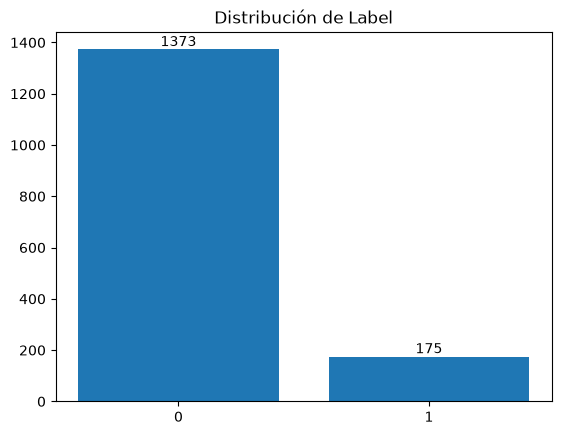

In [6]:
datos = df['label'].value_counts().sort_index()

plt.bar(datos.index.astype(str), datos.values)
plt.title("Distribución de Label")

# Valores de cada categoría
for i, valor in enumerate(datos.values):
    plt.text(i, valor, str(valor), ha="center", va="bottom")

plt.show()


Se puede observar el desbalance que tiene nuestro Target con apenas el 10% de rechazos

### Observar cantidad de nulos

In [7]:
df.isnull().sum() / len(df)*100 #Porcentaje de nulos

Ind_ID              0.000000
GENDER              0.452196
Car_Owner           0.000000
Propert_Owner       0.000000
CHILDREN            0.000000
Annual_income       1.485788
Type_Income         0.000000
EDUCATION           0.000000
Marital_status      0.000000
Housing_type        0.000000
Birthday_count      1.421189
Employed_days       0.000000
Mobile_phone        0.000000
Work_Phone          0.000000
Phone               0.000000
EMAIL_ID            0.000000
Type_Occupation    31.524548
Family_Members      0.000000
label               0.000000
dtype: float64

<Axes: >

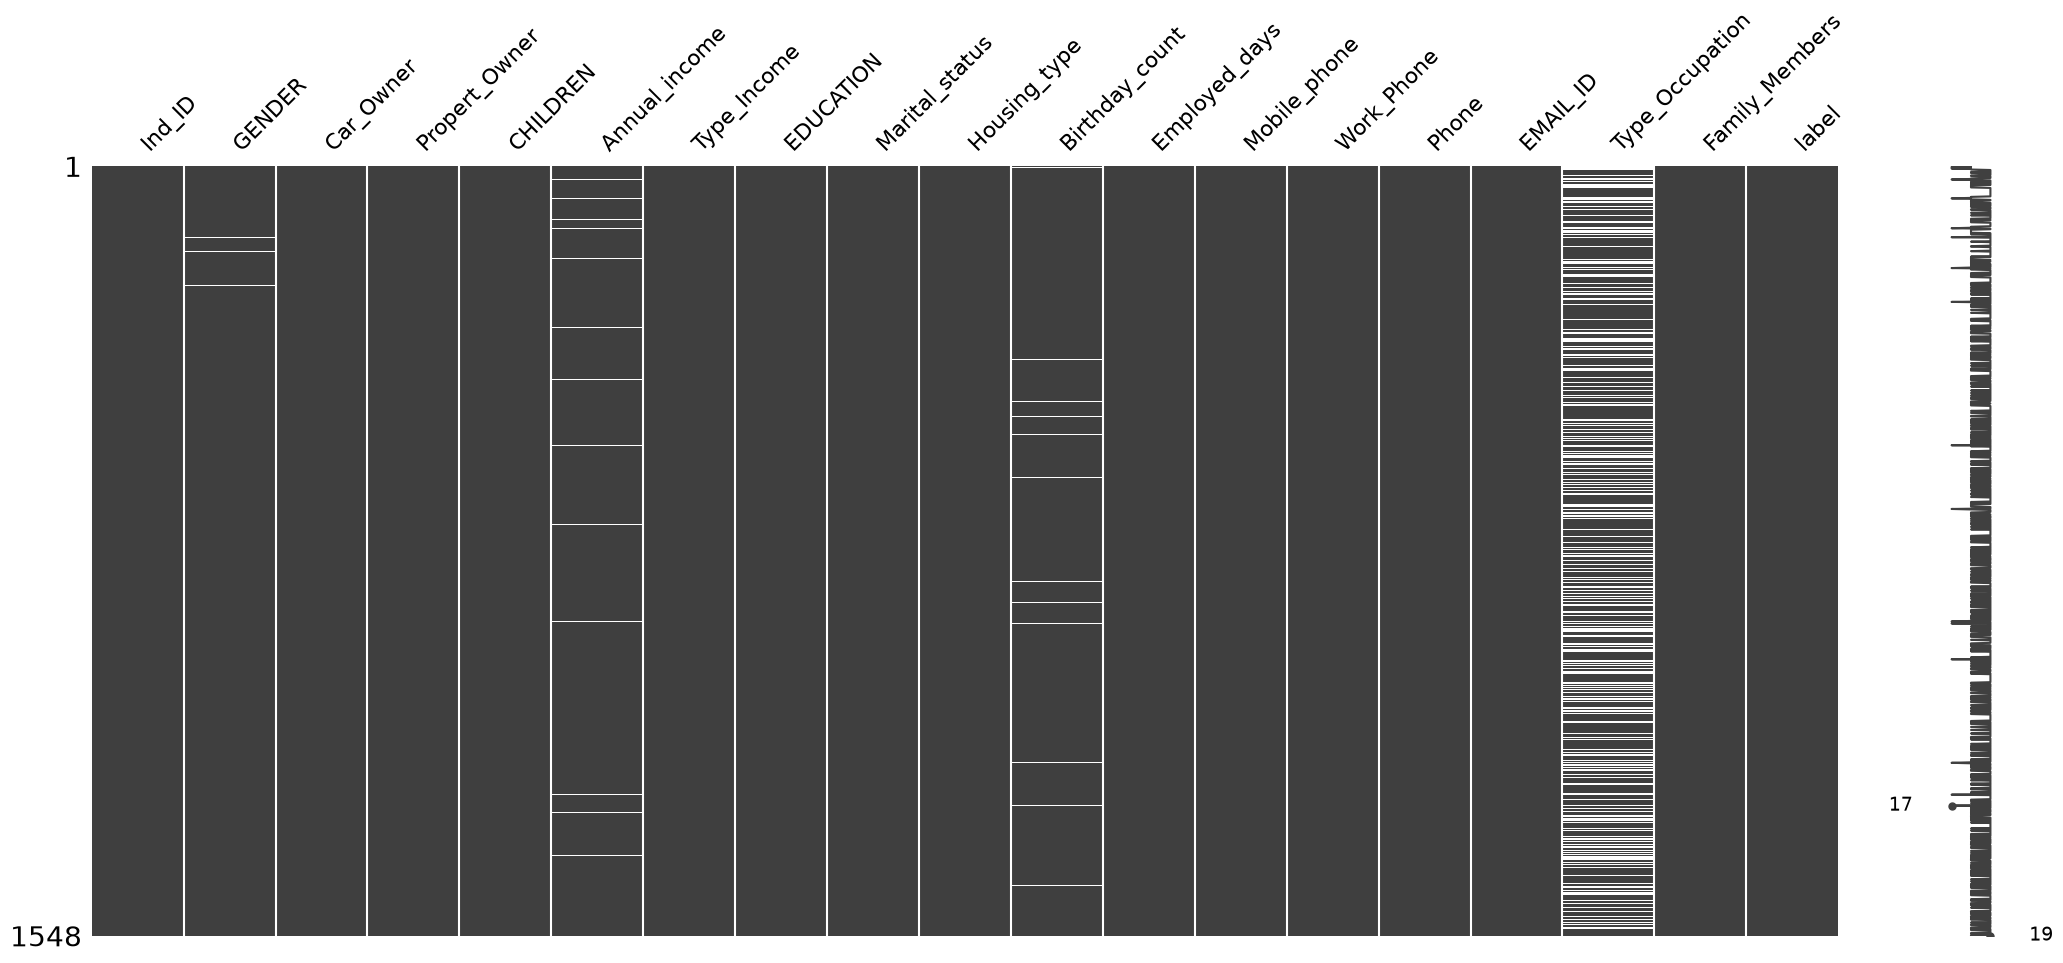

In [8]:
msno.matrix(df)

# Análisis `Type_Occupation`

In [9]:
df['Type_Occupation'].isnull().value_counts()

Type_Occupation
False    1060
True      488
Name: count, dtype: int64

El 31.52% de nulos de `Type_Occupation` son en total 488 

In [10]:
df[df['Employed_days'] > 0]['Type_Occupation'].isnull().value_counts() # > 0 = Desempleados

Type_Occupation
True    261
Name: count, dtype: int64

Todas las personas que son desempleadas tienen puesto null en `Type_Occupation`, pero esas 277 personas restantes son empleadas y también tienen puesto null, así que no se podría considerar que todos los null son sin empleo. Analicemos estos dos grupos:

#### Desempleados con null

In [11]:
df[df['Employed_days'] > 0]['Type_Income'].value_counts() # df[df['Employed_days'] > 0] = Desempleados

Type_Income
Pensioner    261
Name: count, dtype: int64

**Todos los desempleados tienen que su fuente anual es por pensión**

#### Empleados con null

In [12]:
df[(df['Employed_days'] < 0) & (df['Type_Occupation'].isnull())][['Type_Income']].value_counts()

Type_Income         
Working                 129
Commercial associate     77
State servant            18
Pensioner                 3
Name: count, dtype: int64

**Para solucionar este problema, colocaremos como "Desempleado" a todos los "Pensioner" y como "Desconocido" a todos los otros tipo de ingreso**

In [13]:
df['Type_Occupation'] = df['Type_Occupation'].fillna('Desconocido').where(df['Type_Income'] != 'Pensioner', df['Type_Occupation'])  # where → si NO cumple la condición, coloca el valor. En este caso, fillna coloca a todos los
                                                                                                                                    # Null como Desconocido, entonces a los que no cumplen la condición, es decir, todos lo que sean 
                                                                                                                                    # Pensioner, les va a dar un nuevo valor que es el mismo del dataset

In [14]:
df['Type_Occupation'] = df['Type_Occupation'].fillna('Desempleado')

In [15]:
df['Type_Occupation'].value_counts()

Type_Occupation
Laborers                 268
Desempleado              264
Desconocido              224
Core staff               174
Managers                 136
Sales staff              122
Drivers                   86
High skill tech staff     65
Medicine staff            50
Accountants               44
Security staff            25
Cleaning staff            22
Cooking staff             21
Private service staff     17
Low-skill Laborers         9
Secretaries                9
Waiters/barmen staff       5
HR staff                   3
IT staff                   2
Realty agents              2
Name: count, dtype: int64

## Análisis de `GENDER`, `Birthday_count` y `Annual_income`

Es importante determinar si los nulos en las otras categorías también tienen un patrón concreto. Para ello, necesitamos una variable que sea indispensable en este dataset y que esté completa, por ejemplo `Type_Income`. Analizaremos su distribución en todo el dataset y dentro de los nulos para buscar una semejanza. De no ser así, estos nulos pudiesen ser ingresados voluntariamente

In [16]:
df.isnull().sum() / len(df)*100

Ind_ID             0.000000
GENDER             0.452196
Car_Owner          0.000000
Propert_Owner      0.000000
CHILDREN           0.000000
Annual_income      1.485788
Type_Income        0.000000
EDUCATION          0.000000
Marital_status     0.000000
Housing_type       0.000000
Birthday_count     1.421189
Employed_days      0.000000
Mobile_phone       0.000000
Work_Phone         0.000000
Phone              0.000000
EMAIL_ID           0.000000
Type_Occupation    0.000000
Family_Members     0.000000
label              0.000000
dtype: float64

In [17]:
df['Type_Income'].value_counts(normalize=True) # normalize = True → sirve para que me de el resultado en porcentaje. La suma de todos debe dar 1

Type_Income
Working                 0.515504
Commercial associate    0.235788
Pensioner               0.173773
State servant           0.074935
Name: proportion, dtype: float64

In [18]:
df[(df['Annual_income'].isnull())]['Type_Income'].value_counts(normalize=True)

Type_Income
Working                 0.478261
Commercial associate    0.347826
Pensioner               0.173913
Name: proportion, dtype: float64

In [19]:
df[df['Birthday_count'].isnull()]['Type_Income'].value_counts(normalize=True)

Type_Income
Working                 0.681818
Pensioner               0.181818
Commercial associate    0.136364
Name: proportion, dtype: float64

In [20]:
df[df['GENDER'].isnull()]['Type_Income'].value_counts(normalize=True)

Type_Income
Working                 0.428571
Pensioner               0.285714
State servant           0.142857
Commercial associate    0.142857
Name: proportion, dtype: float64

Podemos observar que la mayoría de distribuciones son parecidas, exceptuando unas pequeñas variaciones que se las omite al tener un número de muestro tan bajo. Por ello, concluímos que estos nulos pertenecen a algún error de muestreo.

Para solucionar los nulos en `GENDER`, los reemplazaremos con la moda al ser un string.

In [21]:
df['GENDER'] = df['GENDER'].fillna(df['GENDER'].mode()[0])

#### Histograma de `Annual_income` y `Birthday_count`

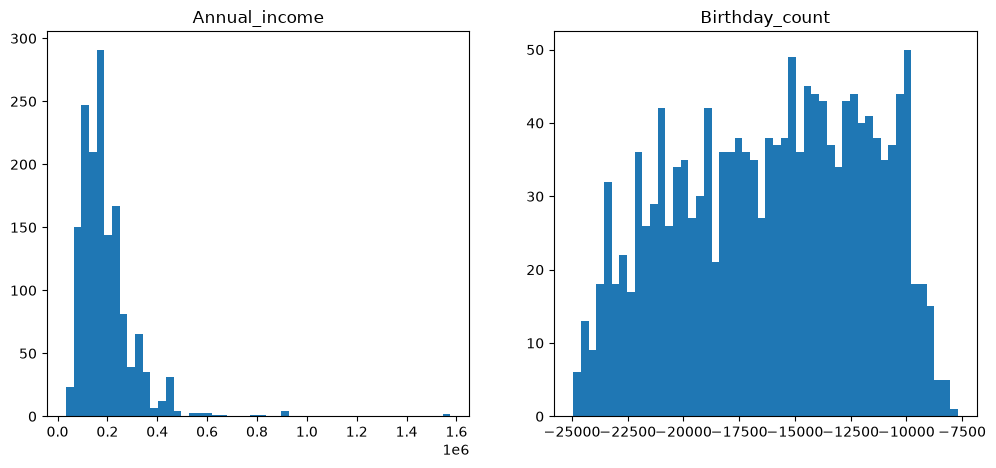

In [22]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.title('Annual_income')
plt.hist(df['Annual_income'], bins=50)

plt.subplot(1,2,2)
plt.title('Birthday_count')
plt.hist(df['Birthday_count'], bins=50)
plt.show()

La opción más factible para reemplazar los nulos en estas variables sería la mediana, ya que nos garantiza obtener el valor real central cuando tenemos valores extremos muy marcados

In [23]:
df['Annual_income'] = df['Annual_income'].fillna(df['Annual_income'].median())
df['Birthday_count'] = df['Birthday_count'].fillna(df['Birthday_count'].median())

In [24]:
df.isnull().sum()

Ind_ID             0
GENDER             0
Car_Owner          0
Propert_Owner      0
CHILDREN           0
Annual_income      0
Type_Income        0
EDUCATION          0
Marital_status     0
Housing_type       0
Birthday_count     0
Employed_days      0
Mobile_phone       0
Work_Phone         0
Phone              0
EMAIL_ID           0
Type_Occupation    0
Family_Members     0
label              0
dtype: int64